<a href="https://colab.research.google.com/github/MariaMinottaZ/NLP-university-project/blob/main/NLP_university_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Importación drive, cargar dataset, importar librerías

Importar drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


Cargar el dataset

In [ ]:
import random
import pandas as pd

records_in_file = 568454 #number of records in file
sample_size = 5000 #desired sample size
filename = "Reviews.csv"
random.seed(101) # initialize the random number generator.
skip = sorted(random.sample(range(1,records_in_file+1),records_in_file-sample_size))
df = pd.read_csv('/content/drive/My Drive/Proyecto2BigData_MariaJoseMinotta/Reviews.csv', skiprows=skip)

Cargar librerías

In [ ]:
import os
from collections import Counter
import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import random
from pylab import rcParams
from wordcloud import WordCloud
from nltk import word_tokenize
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer

# Ejercicio 1

Obtención de las reviews

In [ ]:
reviews = df.Text

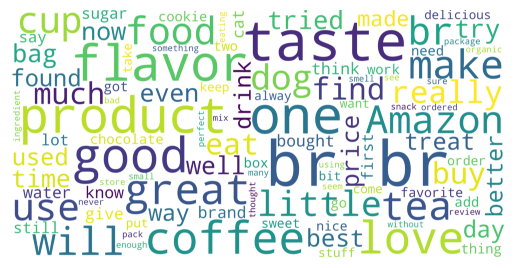

In [ ]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud
word_cloud_text = ''.join(reviews)
wordcloud = WordCloud(max_font_size=100, max_words=100, background_color="white",\
scale = 10,width=800, height=400).generate(word_cloud_text)
plt.figure()
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.show()

# Ejercico 2

No parece ser buena idea por los siguientes motivos:

-Los saltos de linea se consideran como terminan luciendo así: "br" y se podría procesar la palabra br como una verdadera palabra lo cual puede traer problemas.
-Se pueden crear n-gramas de diferentes oraciones si no se tienen en cuenta las comas, los puntos, los paréntesis, etc.
-Hay carácteres especiales que tienen significado y si se eliminan puede perder valor el procesamiento.
-Se pueden crear n-gramas de diferentes oraciones si no se tienen en cuenta las comas, los puntos, los paréntesis, etc.

Sin embargo puede hacerse reemplazando y eliminando algunos tokens antes.


# Ejercicio 3

## Número palabras por review

Obtener palabras por reviews

<Axes: >

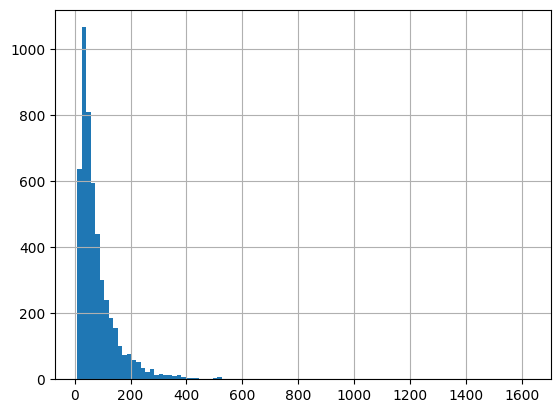

In [ ]:
# Getting the number of words by splitting them by a space
words_per_review = df.Text.apply(lambda x: len(x.split(" ")))
words_per_review.hist(bins = 100)

Obtener media de palabras por review

In [ ]:
words_per_review.mean()

82.3736

Distribución de calificaciones por frecuencia

In [ ]:
df.Score.value_counts()

,count
Score,
5,3161
4,739
1,454
3,389
2,257


Distribución de calificaciones por porcentaje

In [ ]:
percent_val = 100 * df.Score.value_counts()/df.shape[0]
percent_val

,count
Score,
5,63.22
4,14.78
1,9.08
3,7.78
2,5.14


Diagrama de barras de distribución

<Axes: xlabel='Score'>

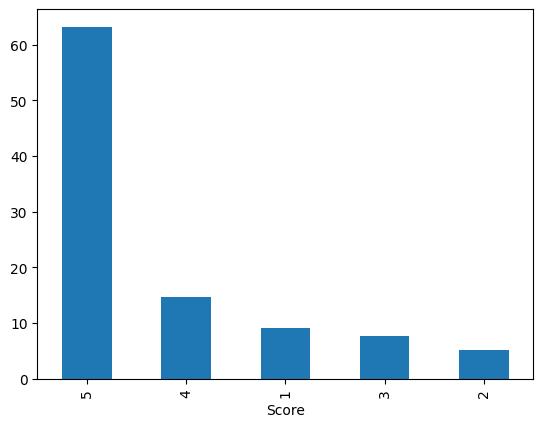

In [ ]:
percent_val.plot.bar()

## Columna sentimientos

In [ ]:
import numpy as np

df['Sentiment_rating'] = np.where(df.Score > 3, 1, 0)
df['Sentiment_rating'].value_counts()

,count
Sentiment_rating,
1,3900
0,1100


Eliminación reviews neutrales

In [ ]:
# Removing neutral reviews
df = df[df.Score != 3]
df['Sentiment_rating'].value_counts()

,count
Sentiment_rating,
1,3900
0,711


Gráfico de distribución de sentimientos

<Axes: xlabel='Sentiment_rating'>

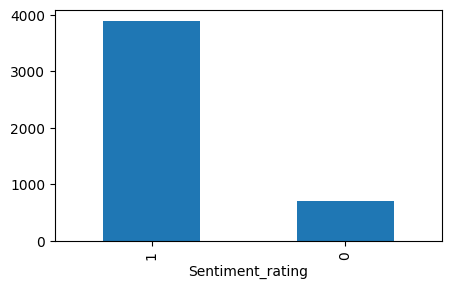

In [ ]:
from pylab import rcParams

rcParams['figure.figsize'] = 5, 3
df.Sentiment_rating.value_counts().plot.bar()

## Preprocesamiento

Pasar a minúscula

In [ ]:
df['reviews_text_new'] = df.Text.apply(lambda x: x.lower())

Tokenizar

In [ ]:
from nltk import word_tokenize
import nltk

nltk.download('punkt')
token_lists = [word_tokenize(each) for each in df.Text]
tokens = [item for sublist in token_lists for item in sublist]
print("Number of unique tokens then: ", len(set(tokens)))
token_lists_lower = [word_tokenize(each) for each in df.reviews_text_new]
tokens_lower = [item for sublist in token_lists_lower for item in sublist]

print("Number of unique tokens now: ", len(set(tokens_lower)))

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


Number of unique tokens then:  20598
Number of unique tokens now:  17083


Quitar carácteres especiales

In [ ]:
import re
review_backup = df.reviews_text_new.copy()
df.reviews_text_new = df.reviews_text_new.apply(
lambda x: re.sub('[^A-Za-z0-9 ]+', ' ', x)
)

Comparar con cantidad de tokens antes

In [ ]:
token_lists = [word_tokenize(each) for each in df.Text]
tokens = [item for sublist in token_lists for item in sublist]
print("Number of unique tokens then: ", len(set(tokens)))
token_lists = [word_tokenize(each) for each in df.reviews_text_new]
tokens = [item for sublist in token_lists for item in sublist]
print("Number of unique tokens now: ", len(set(tokens)))

Number of unique tokens then:  20598
Number of unique tokens now:  14315


Agregar a noisewords las stopwords

In [ ]:
import nltk
nltk.download('stopwords')
noise_words = []

stopwords_corpus = nltk.corpus.stopwords
eng_stop_words = stopwords_corpus.words('english')
noise_words.extend(eng_stop_words)
print(len(noise_words))
noise_words

179


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


['i',
 'me',
 'my',
 'myself',
 'we',
 'our',
 'ours',
 'ourselves',
 'you',
 "you're",
 "you've",
 "you'll",
 "you'd",
 'your',
 'yours',
 'yourself',
 'yourselves',
 'he',
 'him',
 'his',
 'himself',
 'she',
 "she's",
 'her',
 'hers',
 'herself',
 'it',
 "it's",
 'its',
 'itself',
 'they',
 'them',
 'their',
 'theirs',
 'themselves',
 'what',
 'which',
 'who',
 'whom',
 'this',
 'that',
 "that'll",
 'these',
 'those',
 'am',
 'is',
 'are',
 'was',
 'were',
 'be',
 'been',
 'being',
 'have',
 'has',
 'had',
 'having',
 'do',
 'does',
 'did',
 'doing',
 'a',
 'an',
 'the',
 'and',
 'but',
 'if',
 'or',
 'because',
 'as',
 'until',
 'while',
 'of',
 'at',
 'by',
 'for',
 'with',
 'about',
 'against',
 'between',
 'into',
 'through',
 'during',
 'before',
 'after',
 'above',
 'below',
 'to',
 'from',
 'up',
 'down',
 'in',
 'out',
 'on',
 'off',
 'over',
 'under',
 'again',
 'further',
 'then',
 'once',
 'here',
 'there',
 'when',
 'where',
 'why',
 'how',
 'all',
 'any',
 'both',
 'each

Obtención cantidad de tokens del 1%

In [ ]:
tokens = [item for sublist in token_lists for item in sublist]

cantidad = len(set(tokens))/100

Agregar top 1% más frecuentes y menos frecuentes

In [ ]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
import re
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords')

def is_only_alphabet(text):
    return bool(re.fullmatch(r'[a-zA-Z\s]+', text))

df_filtered = df[df['Text'].apply(is_only_alphabet)]

vec = CountVectorizer()
X = vec.fit_transform(df_filtered['Text'])
df_word_matrix = pd.DataFrame(X.toarray(), columns=vec.get_feature_names_out())

df_transposed = df_word_matrix.T
word_frequencies = df_transposed.sum(axis=1)

word_freq_df = pd.DataFrame({
    'word': word_frequencies.index,
    'frequency': word_frequencies.values
})

word_freq_df = word_freq_df.sort_values(by='frequency', ascending=False)

cantidad = 10
topleast = word_freq_df.head(cantidad)
topmost = word_freq_df.tail(cantidad)

stop_words = set(stopwords.words('english'))

noise_words = []
noise_words.extend([word for word in topleast['word'] if word.lower() not in stop_words])

print("Most frequent words (excluding stopwords):")
print(topleast)

noise_words.extend([word for word in topmost['word'] if word.lower() not in stop_words])

print("\nLeast frequent words (excluding stopwords):")
print(topmost)

print("\nNoise words:")
print(noise_words)



[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Most frequent words (excluding stopwords):
        word  frequency
125       to         11
8        and         10
117      the          9
121     this          7
61        it          7
59        is          7
94   product          5
51      good          5
83       not          4
48       get          4

Least frequent words (excluding stopwords):
         word  frequency
56     honest          1
54   handling          1
53        had          1
50     gluten          1
49       glad          1
46      fresh          1
45      found          1
42       find          1
41      every          1
148     yummy          1

Noise words:
['product', 'good', 'get', 'honest', 'handling', 'gluten', 'glad', 'fresh', 'found', 'find', 'every', 'yummy']


# Ejercicio 4

Partición de datos

In [ ]:
from sklearn.model_selection import train_test_split

bow_counts = CountVectorizer(
tokenizer=word_tokenize,
stop_words=noise_words,
ngram_range=(1, 1)
)

reviews_train, reviews_test = train_test_split(df, test_size=0.2, random_state=0)
X_train_bow = bow_counts.fit_transform(reviews_train.reviews_text_new)
X_test_bow = bow_counts.transform(reviews_test.reviews_text_new)

/usr/local/lib/python3.10/dist-packages/sklearn/feature_extraction/text.py:521: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


In [ ]:
y_train_bow = reviews_train['Sentiment_rating']
y_test_bow = reviews_test['Sentiment_rating']
y_test_bow.value_counts() / y_test_bow.shape[0]

,count
Sentiment_rating,
1,0.84182
0,0.15818


Entrenar modelo

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score

# Training the model
lr_model_all = LogisticRegression(C=1, solver="liblinear")
lr_model_all.fit(X_train_bow, y_train_bow)
# Predicting the output
test_pred_lr_prob = lr_model_all.predict_proba(X_test_bow)
test_pred_lr_all = lr_model_all.predict(X_test_bow)
print("F1 score: ", f1_score(y_test_bow, test_pred_lr_all))
print("Accuracy: ", accuracy_score(y_test_bow, test_pred_lr_all) * 100)

F1 score:  0.9383647798742139
Accuracy:  89.38244853737811


In [ ]:
probabilities = [each[1] for each in test_pred_lr_prob]
predictions = pd.DataFrame()
predictions['Text'] = reviews_test['Text']
predictions['Actual_Score'] = reviews_test['Score']
predictions['Sentiment_rating'] = reviews_test['Sentiment_rating']
predictions['Predicted_sentiment'] = test_pred_lr_all
predictions['Predicted_probability'] = probabilities

In [ ]:
predictions.head(5)

,Text,Actual_Score,Sentiment_rating,Predicted_sentiment,Predicted_probability
2719,I honestly wish the other reviewer would have ...,5,1,1,0.999936
3602,Butterfinger hot chocolate is very good. It ta...,5,1,1,0.996193
409,These are so tasty and just the right amount o...,5,1,1,0.999667
3341,"Salsa Verde is my favorite Doritos flavor, but...",5,1,1,0.999906
3108,"As a Native American who is from Seattle, I wa...",1,0,0,0.149303


Muestra de falsos negativos

In [ ]:
import pandas as pd


false_negatives = predictions[
    (predictions['Sentiment_rating'] == 1) &
    (predictions['Predicted_sentiment'] == 0) &
    (predictions['Predicted_probability'] <= 0.5)
]

sample_reviews = false_negatives.sample(n=8) if len(false_negatives) >= 8 else false_negatives

for index, row in sample_reviews.iterrows():
    print(f"Oración {index}:")
    print(f"Review Text: {row['Text']}\n")
    print(f"Actual Sentiment Rating: {row['Sentiment_rating']}")
    print(f"Predicted Sentiment: {row['Predicted_sentiment']}")
    print(f"Predicted Probability: {row['Predicted_probability']:.2f}\n")

Oración 3360:
Review Text: I have to say this is an unusual product.  It's made on the same order as a deodorant and the dog licks the roller to get the flavoring.  We got the liver flavor and all the dogs loved it.  In fact, there was some times when two dogs were trying to lick the roller at the same time since they can't seem to wait their turn.  It's definitely something to try...don't know how well it would do training your dog instead of the regular treats, though.  It'll probably get gross after a few lickings too but a damp paper towel should fix it up...especially if you wipe it after the dog uses it.<br /><br />Unfortunately, I can't comment if it really tastes like liver flavor.  The dog's aren't talking but they definitely seem to like it...<br /><br />Oh yeah, and its made in the USA!

Actual Sentiment Rating: 1
Predicted Sentiment: 0
Predicted Probability: 0.01

Oración 1066:
Review Text: I came across these crackers in a local market and decided to give them a shot. I ha

Motivos:

-El modelo puede clasificar como negativo si está clasificada erróneamente desde un comienzo.

-Se usan palabras que podrían usarse comúnmente más en una negativa que en una positiva

# Tdf-Idf, embedding, etc...

Bag of words

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_counts = TfidfVectorizer(
tokenizer=word_tokenize,
ngram_range=(1,4)
)
X_train_tfidf = tfidf_counts.fit_transform(reviews_train.reviews_text_new)
X_test_tfidf = tfidf_counts.transform(reviews_test.reviews_text_new)

/usr/local/lib/python3.10/dist-packages/sklearn/feature_extraction/text.py:521: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


Regresión logística

In [ ]:
# Create the classifier
lr_model_tf_idf = LogisticRegression(solver="liblinear")
# Train the classifier
lr_model_tf_idf.fit(X_train_tfidf, y_train_bow)
# Predict the results
test_pred_lr_prob = lr_model_tf_idf.predict_proba(X_test_tfidf)
test_pred_lr_all = lr_model_tf_idf.predict(X_test_tfidf)
## Evaluating the model
print("F1 score: ",f1_score(y_test_bow, test_pred_lr_all))
print("Accuracy: ", accuracy_score(y_test_bow, test_pred_lr_all) * 100)

F1 score:  0.9141176470588235
Accuracy:  84.18201516793066


Word embeddings

In [ ]:
import gensim
# Loading a pre-trained glove word embedding that is trained on a Twitter dataset
# This word embedding is 200 dimensional, meaning that each word is represented
# by a 200 dimensional vector.
path_to_glove = '/content/drive/My Drive/Proyecto2BigData_MariaJoseMinotta/glove.twitter.27B.200d_out.txt'
model = gensim.models.KeyedVectors.load_word2vec_format(
path_to_glove,
binary=False,
unicode_errors='ignore'
)

Vector representación de "food"

In [ ]:
print("The embedding for food is", len(model['food']), "dimensional")
model['food']

The embedding for food is 200 dimensional


array([-6.9175e-01, -1.4259e-01,  3.8653e-01, -2.3141e-01, -2.0408e-01,
       -2.1565e-01,  7.7839e-01,  2.2689e-03, -7.2446e-02, -6.0134e-01,
       -4.2400e-01, -5.7140e-01, -8.4249e-01,  1.5947e-01, -1.2899e-01,
        5.9032e-01, -1.3632e-01, -6.6478e-01, -1.9557e-01, -8.2453e-01,
       -1.3177e-01,  1.3514e-01, -7.3214e-01,  4.8200e-01,  4.3505e-01,
        1.6676e+00, -1.8275e-01, -1.0007e-01,  3.7003e-01,  1.0411e-01,
       -8.8115e-01, -9.7733e-04, -2.9459e-01, -7.3869e-02, -4.0103e-01,
       -4.6626e-01,  2.3253e-01,  2.7776e-01,  4.0754e-01, -4.5051e-02,
       -1.9468e-01, -2.9230e-01, -3.4642e-01, -4.9286e-01,  1.0467e-01,
        7.2143e-01,  5.9596e-01,  5.3495e-01,  3.8788e-02, -1.4406e-01,
       -5.2248e-02, -6.8292e-01, -1.0080e-01, -1.2961e-01, -2.6006e-02,
        1.4836e-01,  3.2417e-02,  1.3997e-01,  8.3943e-03, -2.3139e-01,
       -1.8000e-01, -3.1689e-01,  2.3606e-01,  1.8237e-01,  4.3933e-01,
       -3.2313e-01, -2.1512e-03, -4.4172e-01,  4.1011e-01,  1.71

Similitud entre palabras

In [ ]:
def print_similarity(word1, word2, model):
  v1 = model[word1]
  v2 = model[word2]
  similarity = np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2))
  print(f"{word1} and {word2} are {round(similarity * 100)}% similar")

print_similarity("dog", "cat", model)

dog and cat are 83% similar


Creación de review embeddings

In [ ]:
!pip install spacy
!python -m spacy download en_core_web_md


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.8/42.8 MB 15.1 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_md')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
import pandas as pd
import spacy
import numpy as np

nlp = spacy.load('en_core_web_md')

def get_embeddings(text):
    doc = nlp(text)
    return doc.vector


df['embeddings'] = df['Text'].apply(get_embeddings)

df['embedding_mean'] = df['embeddings'].apply(lambda emb: np.mean(emb))

print(df[['Text', 'embedding_mean']])


                                                   Text  embedding_mean
0     Product arrived labeled as Jumbo Salted Peanut...       -0.098364
1     This is a good instant oatmeal from the best o...       -0.061572
2     McCann's Instant Irish Oatmeal, Variety Pack o...       -0.077004
3     these are the best chips out there.. nothing c...       -0.171398
4     I knew my family already liked these chips so ...       -0.112025
...                                                 ...             ...
4995  This is seriously the ONLY food we have purcha...       -0.117916
4996  great product.  actually we've used it all now...       -0.174350
4997  I was having sour throad and as part of the na...       -0.101353
4998  One cannot find a better kipper snack. And, th...       -0.136168
4999  THIS TACO SEASONING WAS RECOMMENDED TO ME AS A...       -0.135161

[4611 rows x 2 columns]


In [ ]:
review_embeddings = df['embedding_mean']

embedding_data = pd.DataFrame(review_embeddings)
embedding_data = embedding_data.fillna(0)
embedding_data.sample(10)

,embedding_mean
1246,-0.051892
3637,-0.052762
834,-0.068474
3520,-0.102131
209,-0.142531
2997,-0.100338
4516,-0.104175
3689,0.023115
1266,-0.049674
3003,-0.159091


In [ ]:
X_train_embed, X_test_embed, y_train_embed, y_test_embed = train_test_split(
embedding_data,
df.Sentiment_rating,
test_size=0.2,
random_state=0
)

In [ ]:
lr_model = LogisticRegression(penalty="l1", C=10, solver="liblinear")
lr_model.fit(X_train_embed, y_train_embed)
test_pred_lr_prob = lr_model.predict_proba(X_test_embed)
test_pred_lr_all = lr_model.predict(X_test_embed)
print("F1 score: ", f1_score(y_test_embed, test_pred_lr_all))
print("Accuracy: ", accuracy_score(y_test_embed, test_pred_lr_all)*100)

F1 score:  0.9141176470588235
Accuracy:  84.18201516793066


# Ejercicio 5

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score

rf_model_tf_idf = RandomForestClassifier(n_estimators=100, random_state=42)

rf_model_tf_idf.fit(X_train_tfidf, y_train_bow)

test_pred_rf_prob = rf_model_tf_idf.predict_proba(X_test_tfidf)
test_pred_rf_all = rf_model_tf_idf.predict(X_test_tfidf)

print("F1 score: ", f1_score(y_test_bow, test_pred_rf_all))
print("Accuracy: ", accuracy_score(y_test_bow, test_pred_rf_all) * 100)


F1 score:  0.9184397163120568
Accuracy:  85.04875406283857


# Ejercicio 6

In [ ]:
from nltk import ngrams
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score
import numpy as np
import pandas as pd

def generate_ngrams_vector(text, ngram_range=(1, 4), vector_size=200):
    ngram_counts = np.zeros(vector_size)
    for n in range(ngram_range[0], ngram_range[1] + 1):
        for ngram in ngrams(text.split(), n):
            index = hash(ngram) % vector_size
            ngram_counts[index] += 1
    return ngram_counts

ngram_vectors = np.vstack(df['Text'].apply(
    lambda x: generate_ngrams_vector(x, ngram_range=(1, 4), vector_size=200)
).values)

combined_data = np.hstack([embedding_data.values, ngram_vectors])

X_train_embed, X_test_embed, y_train_embed, y_test_embed = train_test_split(
    combined_data,
    df['Sentiment_rating'],
    test_size=0.2,
    random_state=0
)

lr_model = LogisticRegression(penalty="l1", C=10, solver="liblinear")
lr_model.fit(X_train_embed, y_train_embed)

test_pred_lr_all = lr_model.predict(X_test_embed)
print("F1 score: ", f1_score(y_test_embed, test_pred_lr_all))
print("Accuracy: ", accuracy_score(y_test_embed, test_pred_lr_all) * 100)

F1 score:  0.9181585677749361
Accuracy:  86.13217768147345


# Ejercicio 7

In [ ]:
import pandas as pd
import numpy as np
import nltk
from nltk.tokenize import word_tokenize

nltk.download('punkt')

def average_embedding(review, model):
    words = word_tokenize(review)
    embeddings = [model[word] for word in words if word in model]
    if not embeddings:
        return np.zeros(200)
    return np.mean(embeddings, axis=0)

df['Average_Embedding'] = df['Text'].apply(lambda x: average_embedding(x, model))

embedding_data = pd.DataFrame(df['Average_Embedding'].tolist(), columns=[f'Embedding_Dim_{i+1}' for i in range(200)])

print(embedding_data)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


      Embedding_Dim_1  Embedding_Dim_2  Embedding_Dim_3  Embedding_Dim_4  \
0            0.056455         0.142048         0.034450         0.253796   
1            0.032637         0.056130         0.058286         0.170323   
2            0.072398         0.039587        -0.099748         0.176379   
3           -0.060526         0.202631        -0.015753         0.175403   
4            0.014822         0.231766         0.017360         0.139247   
...               ...              ...              ...              ...   
4606         0.083538         0.102364         0.049579         0.176211   
4607         0.056765         0.016541        -0.002306         0.147732   
4608         0.097641        -0.032810         0.011639         0.144642   
4609         0.009109         0.071422        -0.049345         0.155525   
4610         0.365113        -0.027686        -0.345753         0.076320   

      Embedding_Dim_5  Embedding_Dim_6  Embedding_Dim_7  Embedding_Dim_8  \
0          